<a href="https://colab.research.google.com/github/But-Vladyslava/Machine-Learning-Uni-/blob/main/%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D1%87%D0%B0%D1%81%D0%BE%D0%B2%D0%B8%D1%85_%D1%80%D1%8F%D0%B4%D1%96%D0%B2_%D0%91%D1%83%D1%82_3_12_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Практикум: аналіз і прогнозування часових рядів

Цей notebook доповнює лекцію **«Аналіз і прогнозування часових рядів. Навчання та оцінка моделі»**.

Мета практикуму — послідовно пройти основні етапи прогнозування:

1. підготовка часових даних;
2. візуальний аналіз;
3. дослідження тренду та сезонності;
4. коректний часовий поділ на train/test;
5. побудова базових прогнозів;
6. оцінювання якості за MAE, RMSE, sMAPE та MASE;
7. застосування ETS;
8. застосування SARIMA;
9. використання Prophet;
10. побудова ML-моделі на лагових і календарних ознаках;
11. покрокова ретроспективна перевірка;
12. самостійні завдання.

**Важливо:** у часових рядах не можна випадково перемішувати спостереження перед поділом на навчальну і тестову вибірки.

## 1. Підключення бібліотек

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.ensemble import HistGradientBoostingRegressor

from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 50)
np.random.seed(42)

## 2. Формування навчального часового ряду

Щоб notebook можна було виконувати без завантаження зовнішніх файлів, використаємо штучно сформований щоденний ряд продажів. Він містить:

- довгостроковий тренд;
- тижневу сезонність;
- річну сезонність;
- підвищення попиту у вихідні;
- випадковий шум;
- декілька аномальних значень.

Такий ряд зручний для демонстрації основних етапів forecasting.

In [2]:
dates = pd.date_range("2022-01-01", "2025-12-31", freq="D")
n = len(dates)
t = np.arange(n)

trend = 100 + 0.035 * t
weekly = 12 * np.sin(2 * np.pi * t / 7)
yearly = 8 * np.sin(2 * np.pi * t / 365.25)
weekend = np.where(dates.dayofweek >= 5, 10, 0)
noise = np.random.normal(0, 6, n)

sales = trend + weekly + yearly + weekend + noise

df = pd.DataFrame({
    "date": dates,
    "sales": sales
})

# Додаємо кілька пропусків та аномалій для демонстрації підготовки даних
missing_idx = [120, 450, 900]
outlier_idx = [300, 700, 1100]

df.loc[missing_idx, "sales"] = np.nan
df.loc[outlier_idx, "sales"] *= 1.7

df.head()

,date,sales
0,2022-01-01,112.980285
1,2022-01-02,118.725005
2,2022-01-03,115.930451
3,2022-01-04,114.862459
4,2022-01-05,94.078518


In [3]:
print(df.shape)
print(df.dtypes)
print("\nКількість пропусків:")
print(df.isna().sum())

(1461, 2)
date     datetime64[ns]
sales           float64
dtype: object

Кількість пропусків:
date     0
sales    3
dtype: int64


### Завдання 1. Первинний аналіз

1. Виведіть останні 10 рядків.
2. Визначте мінімальну та максимальну дату.
3. Обчисліть середнє, медіану, стандартне відхилення, мінімум і максимум `sales`.
4. Перевірте, чи є дублікати дат.

In [4]:
# Ваш код тут

#1
print("\nОстанні 10 рядків:")
display(df.tail(10))

#2
print("\nМінімальна та максимальна дата:")
print("Мінімальна дата:", df['date'].min())
print("Максимальна дата:", df['date'].max())

#3
print("\nСтатистика для sales:")
print(f"Середнє: {df['sales'].mean()}")
print(f"Медіана: {df['sales'].median()}")
print(f"Стандартне відхилення: {df['sales'].std()}")
print(f"Мінімум: {df['sales'].min()}")
print(f"Максимум: {df['sales'].max()}")

#4
print("\nПеревірка на дублікати дат:")
duplicates_count = df['date'].duplicated().sum()
print(f"Кількість дублікатів у стовпчику date: {duplicates_count}")


Останні 10 рядків:


,date,sales
1451,2025-12-22,171.328008
1452,2025-12-23,156.237492
1453,2025-12-24,160.161011
1454,2025-12-25,141.622914
1455,2025-12-26,130.154195
1456,2025-12-27,164.792801
1457,2025-12-28,172.113885
1458,2025-12-29,170.054977
1459,2025-12-30,160.035508
1460,2025-12-31,144.925047



Мінімальна та максимальна дата:
Мінімальна дата: 2022-01-01 00:00:00
Максимальна дата: 2025-12-31 00:00:00

Статистика для sales:
Середнє: 128.86840539993554
Медіана: 128.30740465635068
Стандартне відхилення: 19.969577035218677
Мінімум: 78.05403090053971
Максимум: 279.5724799225864

Перевірка на дублікати дат:
Кількість дублікатів у стовпчику date: 0


## 3. Підготовка часових даних

Для подальшого аналізу необхідно:

- перетворити дату у формат `datetime`;
- відсортувати дані;
- зробити дату індексом;
- перевірити регулярність часового кроку;
- обробити пропущені значення.

У цьому прикладі пропуски заповнюються часовою інтерполяцією.

In [5]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").drop_duplicates(subset="date")
df = df.set_index("date")

print(pd.infer_freq(df.index))

df["sales"] = df["sales"].interpolate(method="time")

print("Пропусків після інтерполяції:", df["sales"].isna().sum())
df.head()

D
Пропусків після інтерполяції: 0


,sales
date,
2022-01-01,112.980285
2022-01-02,118.725005
2022-01-03,115.930451
2022-01-04,114.862459
2022-01-05,94.078518


### Завдання 2. Робота з пропусками

Створіть копію набору даних `df_task` і штучно видаліть значення `sales` для п'яти довільних дат.

Порівняйте три способи заповнення:

- `ffill`;
- лінійну інтерполяцію;
- часову інтерполяцію.

Коротко поясніть, який спосіб доцільніший для цього ряду.

In [13]:
# Ваш код тут

df_clean = df.reset_index(drop=False) if 'date' in df.columns else df.reset_index()

df_task = df_clean.copy()
df_task.loc[df_task.index[[10, 20, 30, 40, 50]], 'sales'] = np.nan

df_ffill = df_task.copy()
df_ffill['sales'] = df_ffill['sales'].ffill()

df_linear = df_task.copy()
df_linear['sales'] = df_linear['sales'].interpolate(method='linear')

df_time = df_task.copy().set_index('date')
df_time['sales'] = df_time['sales'].interpolate(method='time')
df_time = df_time.reset_index()

Найдоцільнішою є часова інтерполяція (method='time'), оскільки вона враховує реальні часові інтервали між датами, це є критично важливим для часових рядів.

## 4. Візуальний аналіз

Графік часового ряду є першим інструментом діагностики. За ним оцінюють:

- загальний напрям зміни;
- сезонні коливання;
- можливі структурні зміни;
- викиди;
- зміну дисперсії.

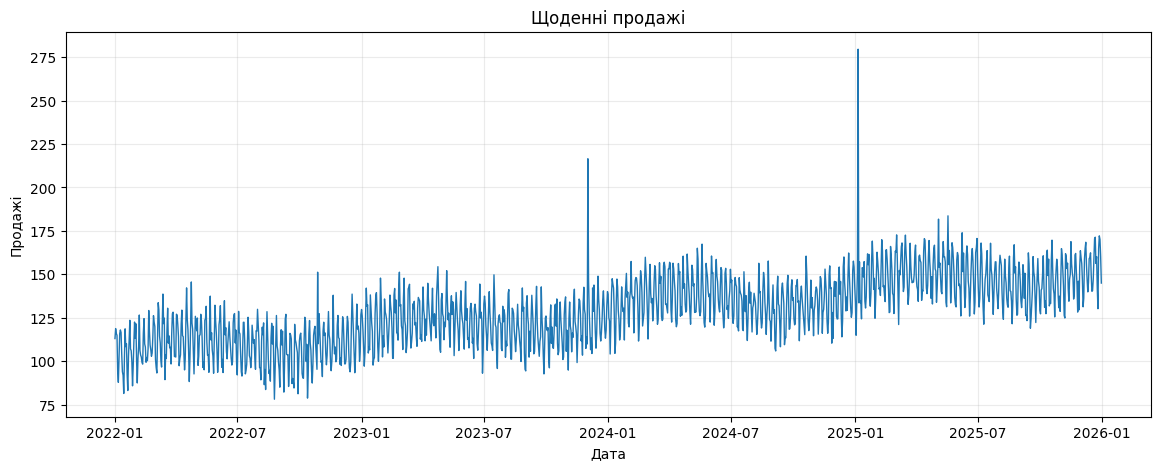

In [14]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(df.index, df["sales"], linewidth=1)
ax.set_title("Щоденні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Продажі")
ax.grid(alpha=0.25)
plt.show()

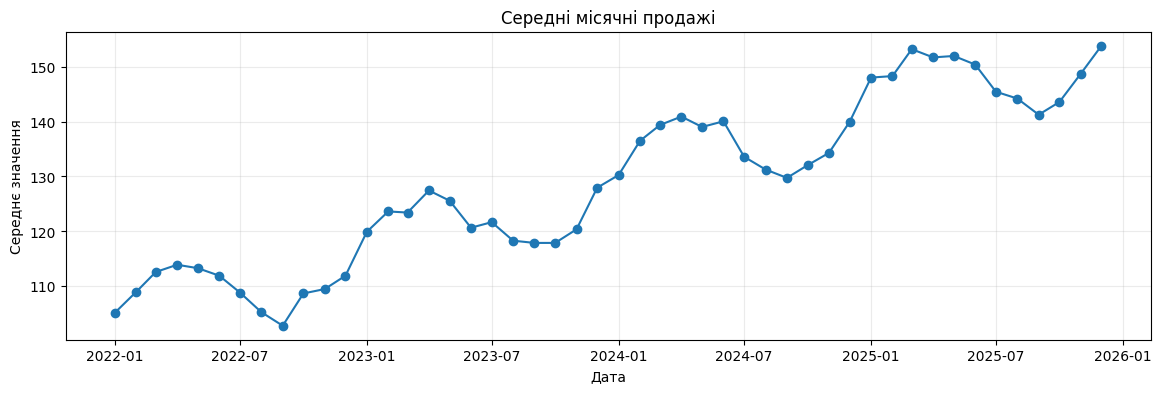

In [15]:
monthly = df["sales"].resample("MS").mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly.values, marker="o")
ax.set_title("Середні місячні продажі")
ax.set_xlabel("Дата")
ax.set_ylabel("Середнє значення")
ax.grid(alpha=0.25)
plt.show()

### Завдання 3. Візуалізація

1. Побудуйте графік останніх 90 днів.
2. Побудуйте 7-денне та 30-денне ковзні середні.
3. Поясніть, чим відрізняється інформація на цих двох графіках.

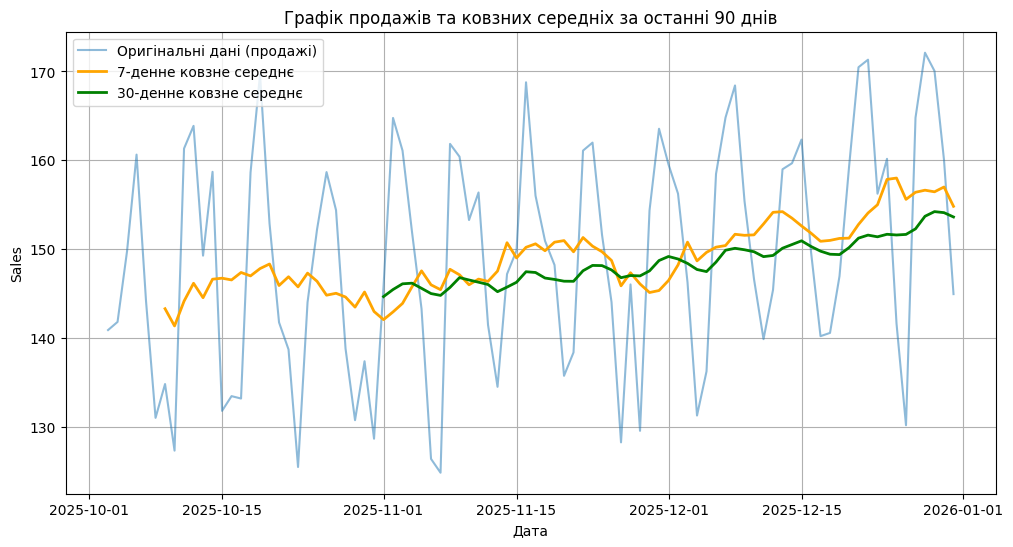

In [18]:
# Ваш код тут

import matplotlib.pyplot as plt

df_plot = df.reset_index() if 'date' not in df.columns and 'sales' not in df.columns else df.copy()

if 'date' not in df_plot.columns:
    df_plot = df_plot.reset_index()



df_last90 = df_plot.tail(90)

rolling_7 = df_last90['sales'].rolling(window=7).mean()
rolling_30 = df_last90['sales'].rolling(window=30).mean()

plt.figure(figsize=(12, 6))
plt.plot(df_last90['date'], df_last90['sales'], label='Оригінальні дані (продажі)', alpha=0.5)
plt.plot(df_last90['date'], rolling_7, label='7-денне ковзне середнє', color='orange', linewidth=2)
plt.plot(df_last90['date'], rolling_30, label='30-денне ковзне середнє', color='green', linewidth=2)

plt.xlabel('Дата')
plt.ylabel('Sales')
plt.title('Графік продажів та ковзних середніх за останні 90 днів')
plt.legend()
plt.grid(True)
plt.show()

7-денне ковзне середнє показує короткострокові зміни і дуже швидко реагує на будь-які тижневі стрибки чи спади, тому воно йде ближче до основного графіка. Натомість 30-денне ковзне середнє працює як фільтр від зайвого шуму та різких коливань, повністю вирівнюючи лінію, завдяки чому на ньому чудово видно загальний глобальний напрямок руху продажів у той чи інший бік протягом місяця.

## 5. Декомпозиція ряду методом STL

STL-декомпозиція розкладає часовий ряд на:

- **trend** — довгострокову тенденцію;
- **seasonal** — сезонну складову;
- **resid** — залишкову складову.

Для щоденних даних з тижневою сезонністю використаємо `period=7`.

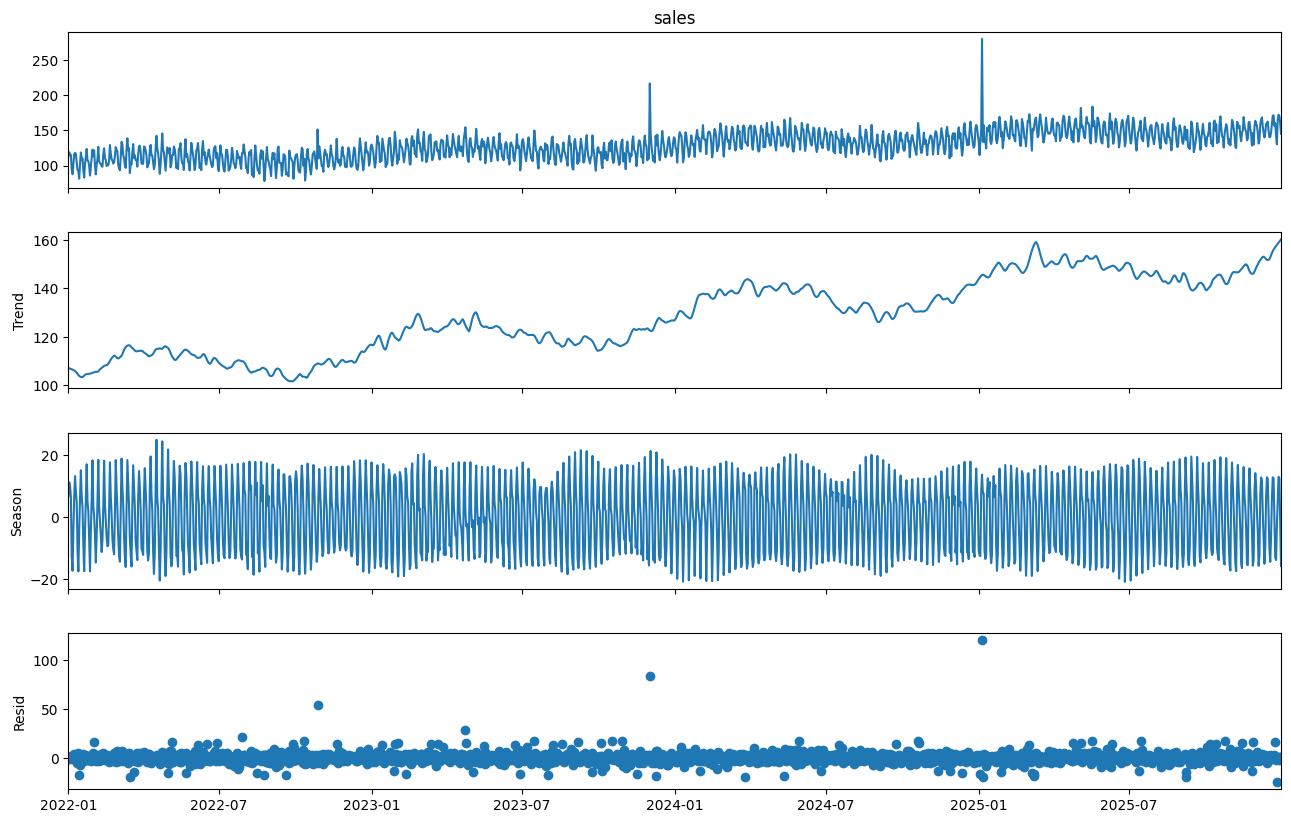

In [19]:
stl = STL(df["sales"], period=7, robust=True)
stl_result = stl.fit()

fig = stl_result.plot()
fig.set_size_inches(14, 9)
plt.show()

### Завдання 4. Декомпозиція

1. Повторіть STL-декомпозицію для місячного ряду.
2. Оберіть обґрунтований період сезонності.
3. Проаналізуйте тренд та залишки.

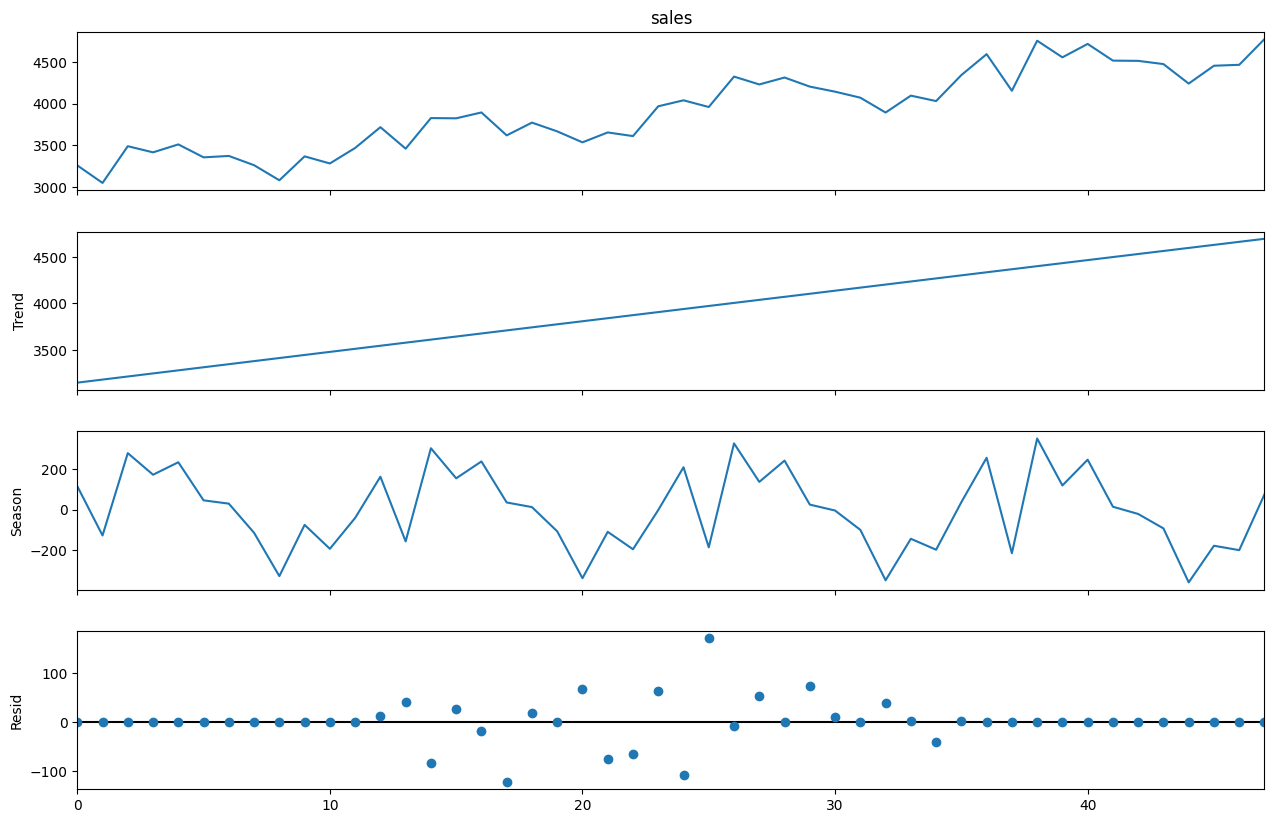

In [21]:
# Ваш код тут

from statsmodels.tsa.seasonal import STL
import matplotlib.pyplot as plt

df_temp = df.reset_index() if 'date' not in df.columns else df.copy()

df_monthly = df_temp.resample('ME', on='date')['sales'].sum().reset_index()

stl_monthly = STL(df_monthly['sales'], period=12, robust=True)
stl_m_result = stl_monthly.fit()

fig = stl_m_result.plot()
fig.set_size_inches(14, 9)
plt.show()

Для місячного ряду обґрунтовано обрано період дванадцять через річний цикл повторюваності даних, тренд демонструє довгострокову глобальну динаміку продажів без урахування сезонності й випадкових коливань, а залишки відображають непередбачуваний шум та аномальні викиди, які не пояснюються жодною із загальних складових.

## 6. Часовий поділ train/test

У звичайних задачах машинного навчання дані часто перемішують. Для часових рядів це зазвичай неприпустимо.

Нехай останні 90 днів становлять тестовий період. Усі попередні спостереження використовуються для навчання.

In [22]:
horizon = 90

train = df.iloc[:-horizon].copy()
test = df.iloc[-horizon:].copy()

print("Train:", train.index.min().date(), "—", train.index.max().date(), len(train))
print("Test :", test.index.min().date(), "—", test.index.max().date(), len(test))

Train: 2022-01-01 — 2025-10-02 1371
Test : 2025-10-03 — 2025-12-31 90


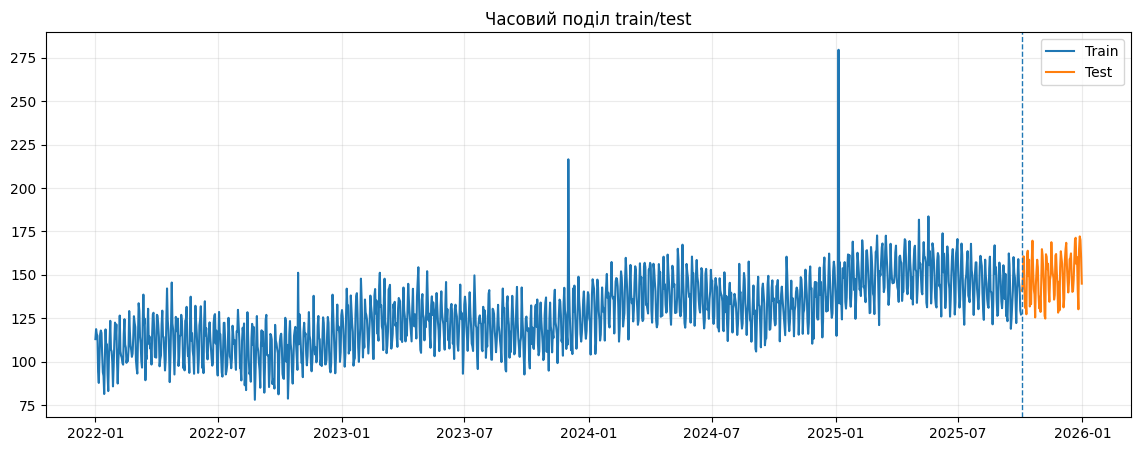

In [23]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index, train["sales"], label="Train")
ax.plot(test.index, test["sales"], label="Test")
ax.axvline(test.index.min(), linestyle="--", linewidth=1)
ax.legend()
ax.set_title("Часовий поділ train/test")
ax.grid(alpha=0.25)
plt.show()

### Завдання 5. Часовий поділ

Створіть інший варіант поділу, у якому тестовий період дорівнює 60 дням.

Виведіть:

- кількість спостережень у train;
- кількість спостережень у test;
- останню дату train;
- першу дату test.

In [25]:
# Ваш код тут

df_split = df.reset_index() if 'date' not in df.columns else df.copy()

test_size = 60

train = df_split.iloc[:-test_size]
test = df_split.iloc[-test_size:]

print("Кількість спостережень у train:", len(train))
print("Кількість спостережень у test:", len(test))
print("Остання дата train:", train['date'].max())
print("Перша дата test:", test['date'].min())

Кількість спостережень у train: 1401
Кількість спостережень у test: 60
Остання дата train: 2025-11-01 00:00:00
Перша дата test: 2025-11-02 00:00:00


## 7. Базові моделі прогнозування

Перед використанням складної моделі потрібно побудувати простий базовий прогноз.

### Naive forecast
Прогноз дорівнює останньому відомому значенню.

### Seasonal naive
Прогноз повторює значення попереднього сезонного циклу. Для щоденних даних з тижневою сезонністю використаємо лаг 7.

In [26]:
naive_pred = np.repeat(train["sales"].iloc[-1], len(test))

history = pd.concat([train["sales"], test["sales"]])
seasonal_naive_pred = history.shift(7).loc[test.index].values

baseline = pd.DataFrame({
    "actual": test["sales"].values,
    "naive": naive_pred,
    "seasonal_naive": seasonal_naive_pred
}, index=test.index)

baseline.head()

,actual,naive,seasonal_naive
1401,164.769682,145.781746,158.669587
1402,161.087756,145.781746,154.378728
1403,151.903340,145.781746,138.789478
1404,143.263305,145.781746,130.725589
1405,126.366294,145.781746,137.363586


## 8. Метрики якості прогнозу

Використаємо:

- **MAE** — середню абсолютну помилку;
- **RMSE** — квадратний корінь із середньоквадратичної помилки;
- **sMAPE** — симетричну відносну помилку;
- **MASE** — масштабовану абсолютну помилку.

Менше значення метрики зазвичай означає кращий прогноз.

In [27]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

def smape(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    denom = (np.abs(y_true) + np.abs(y_pred))
    mask = denom != 0
    return 100 * np.mean(
        2 * np.abs(y_pred[mask] - y_true[mask]) / denom[mask]
    )

def mase(y_true, y_pred, y_train, seasonality=1):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_train = np.asarray(y_train)

    scale = np.mean(
        np.abs(y_train[seasonality:] - y_train[:-seasonality])
    )
    return np.mean(np.abs(y_true - y_pred)) / scale

def evaluate(y_true, y_pred, y_train, seasonality=7):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": rmse(y_true, y_pred),
        "sMAPE_%": smape(y_true, y_pred),
        "MASE": mase(y_true, y_pred, y_train, seasonality)
    }

results = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7)
}).T

results

,MAE,RMSE,sMAPE_%,MASE
Naive,11.389437,13.495810,7.595040,1.601393
Seasonal naive,7.523370,9.241039,5.107073,1.057811


### Завдання 6. Метрики

1. Визначте, яка базова модель є кращою.
2. Поясніть, чому висновок не слід робити лише за однією метрикою.
3. Обчисліть MAE окремо для перших і останніх 30 днів тестового періоду.

In [30]:
# Ваш код тут

from sklearn.metrics import mean_absolute_error

test_first_30 = test.iloc[:30]
test_last_30 = test.iloc[30:]

# Прогнози для обох частин (на прикладі Seasonal naive)
snaive_f30_pred = seasonal_naive_pred[:30]
snaive_l30_pred = seasonal_naive_pred[30:]

# Обчислення MAE окремо для перших і останніх 30 днів
mae_first_30 = mean_absolute_error(test_first_30["sales"], snaive_f30_pred)
mae_last_30 = mean_absolute_error(test_last_30["sales"], snaive_l30_pred)

print(f"MAE для перших 30 днів: {mae_first_30:.4f}")
print(f"MAE для останніх 30 днів: {mae_last_30:.4f}")

MAE для перших 30 днів: 8.2790
MAE для останніх 30 днів: 6.7678


Найкращою базовою моделлю є Seasonal naive, оскільки вона має менші показники помилок за всіма метриками, проте висновок не можна робити лише за однією метрикою, бо кожна з них оцінює якість прогнозу з різних боків, а окремий розрахунок MAE для перших і останніх тридцяти днів тестового періоду дозволяє побачити, чи не погіршується точність моделі з часом у міру віддалення від навчальних даних.

## 9. Експоненційне згладжування ETS

Моделі ETS описують часовий ряд через рівень, тренд і сезонність.

Для навчального прикладу використаємо:

- адитивний тренд;
- адитивну сезонність;
- сезонний період 7 днів.

In [31]:
ets_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred = ets_model.forecast(len(test))

ets_metrics = evaluate(
    test["sales"],
    ets_pred,
    train["sales"],
    seasonality=7
)

ets_metrics

{'MAE': 6.417537801328749,
 'RMSE': np.float64(7.731200972731346),
 'sMAPE_%': np.float64(4.339169753097103),
 'MASE': np.float64(0.9023274292763365)}

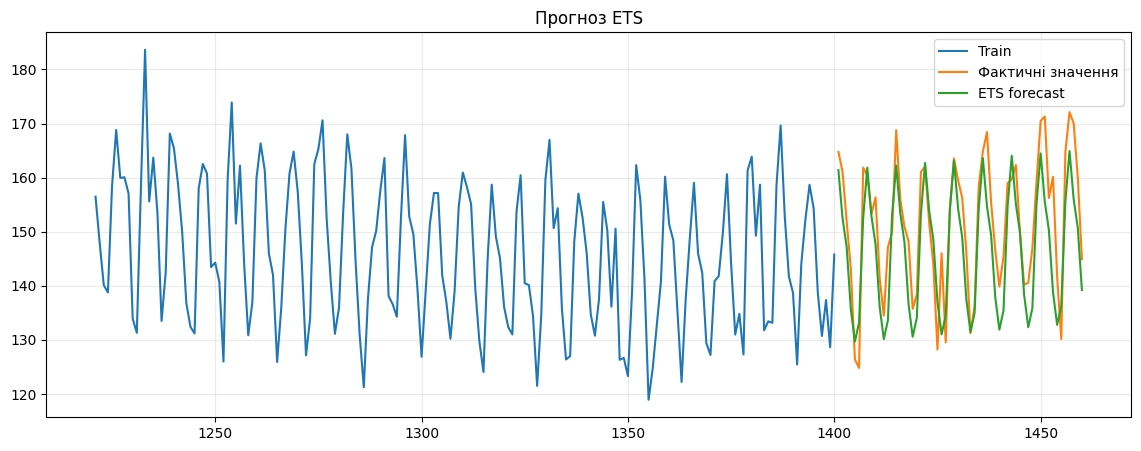

In [32]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, ets_pred, label="ETS forecast")
ax.legend()
ax.set_title("Прогноз ETS")
ax.grid(alpha=0.25)
plt.show()

### Завдання 7. ETS

1. Побудуйте ETS-модель без тренду.
2. Порівняйте її з поточною моделлю.
3. Додайте результати обох ETS-моделей до таблиці метрик.

In [33]:
# Ваш код тут

#1
ets_model_no_trend = ExponentialSmoothing(
    train["sales"],
    trend=None,
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

ets_pred_no_trend = ets_model_no_trend.forecast(len(test))

#2
ets_no_trend_metrics = evaluate(
    test["sales"],
    ets_pred_no_trend,
    train["sales"],
    seasonality=7
)

#3
results.loc["ETS (with trend)"] = ets_metrics
results.loc["ETS (no trend)"] = ets_no_trend_metrics

results

,MAE,RMSE,sMAPE_%,MASE
Naive,11.389437,13.495810,7.595040,1.601393
Seasonal naive,7.523370,9.241039,5.107073,1.057811
ETS (with trend),6.417538,7.731201,4.339170,0.902327
ETS (no trend),8.137105,9.662181,5.524029,1.144104


## 10. SARIMA

SARIMA розширює ARIMA сезонними компонентами.

У загальному випадку модель записують як:

**SARIMA(p, d, q)(P, D, Q, s)**,

де `s` — довжина сезонного циклу.

Нижче використано невелику модель, щоб приклад виконувався відносно швидко.

In [34]:
sarima_model = SARIMAX(
    train["sales"],
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)

sarima_forecast = sarima_model.get_forecast(steps=len(test))
sarima_pred = sarima_forecast.predicted_mean
sarima_ci = sarima_forecast.conf_int()

sarima_metrics = evaluate(
    test["sales"],
    sarima_pred,
    train["sales"],
    seasonality=7
)

sarima_metrics

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


{'MAE': 8.254891279383138,
 'RMSE': np.float64(9.780364385952613),
 'sMAPE_%': np.float64(5.6020102934773455),
 'MASE': np.float64(1.1606655165380095)}

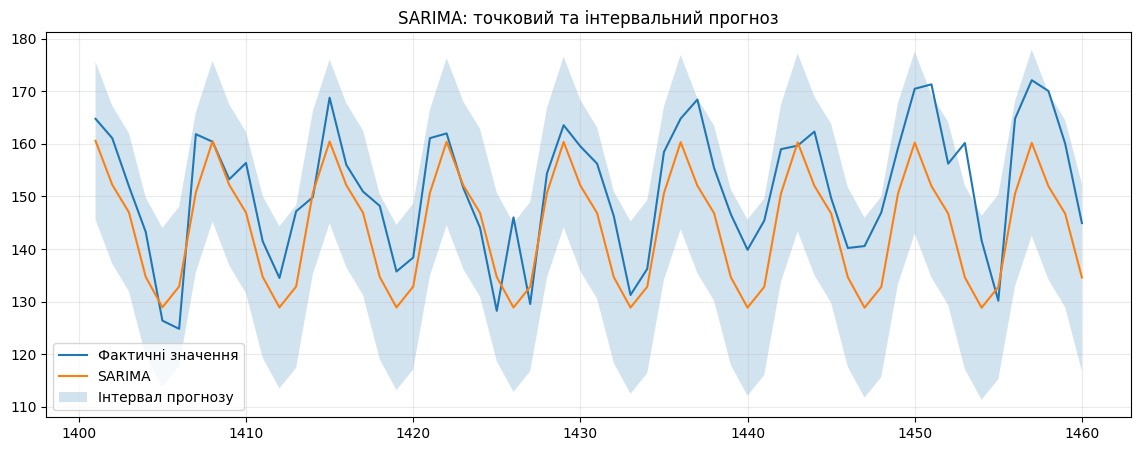

In [35]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, sarima_pred, label="SARIMA")
ax.fill_between(
    test.index,
    sarima_ci.iloc[:, 0].values,
    sarima_ci.iloc[:, 1].values,
    alpha=0.2,
    label="Інтервал прогнозу"
)
ax.legend()
ax.set_title("SARIMA: точковий та інтервальний прогноз")
ax.grid(alpha=0.25)
plt.show()

### Завдання 8. SARIMA

Змініть параметри моделі, наприклад:

- `order=(2, 1, 1)`;
- `seasonal_order=(1, 1, 0, 7)`.

Порівняйте MAE та RMSE з попередньою SARIMA-моделлю.

**Примітка:** мета завдання — зрозуміти вплив параметрів, а не виконати повний автоматичний підбір.

In [36]:
# Ваш код тут

sarima_model_new = SARIMAX(
    train["sales"],
    order=(2, 1, 1),
    seasonal_order=(1, 1, 0, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False)


sarima_forecast_new = sarima_model_new.get_forecast(len(test))
sarima_pred_new = sarima_forecast_new.predicted_mean

sarima_metrics_new = evaluate(
    test["sales"],
    sarima_pred_new,
    train["sales"],
    seasonality=7
)

print("Попередні метрики SARIMA (MAE / RMSE):", f"{sarima_metrics['MAE']:.4f} / {sarima_metrics['RMSE']:.4f}")
print("Нові метрики SARIMA (MAE / RMSE):     ", f"{sarima_metrics_new['MAE']:.4f} / {sarima_metrics_new['RMSE']:.4f}")

Попередні метрики SARIMA (MAE / RMSE): 8.2549 / 9.7804
Нові метрики SARIMA (MAE / RMSE):      8.1782 / 9.7768


## 11. Prophet

Prophet зручно використовувати для рядів з трендом, сезонністю та календарними ефектами.

У Prophet назви основних стовпців мають бути:

- `ds` — дата;
- `y` — цільове значення.

Якщо бібліотека не встановлена, у Google Colab її можна встановити командою:

```python
!pip -q install prophet
```

In [37]:
!pip -q install prophet

In [44]:
# Розкоментуйте, якщо Prophet встановлений.
from prophet import Prophet

prophet_train = (
    train.reset_index()
    .rename(columns={"date": "ds", "sales": "y"})
)

model_prophet = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)

model_prophet.fit(prophet_train)

future = model_prophet.make_future_dataframe(
    periods=len(test),
    freq="D"
)

forecast = model_prophet.predict(future)

prophet_pred = forecast["yhat"].iloc[-len(test):].values

evaluate(
    test["sales"],
    prophet_pred,
    train["sales"],
    seasonality=7
)

{'MAE': 5.0353941326935745,
 'RMSE': np.float64(6.2284678940071485),
 'sMAPE_%': np.float64(3.4095662092313637),
 'MASE': np.float64(0.7079933743757295)}

### Завдання 9. Prophet

Після встановлення `prophet`:

1. навчіть модель;
2. отримайте прогноз на тестовий період;
3. побудуйте графік;
4. виведіть компоненти моделі;
5. порівняйте MAE з ETS та SARIMA.

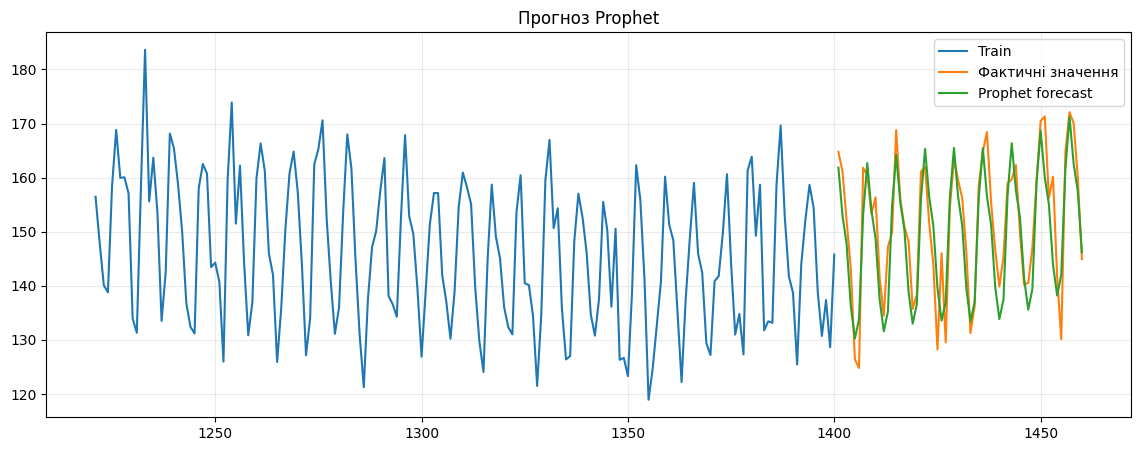

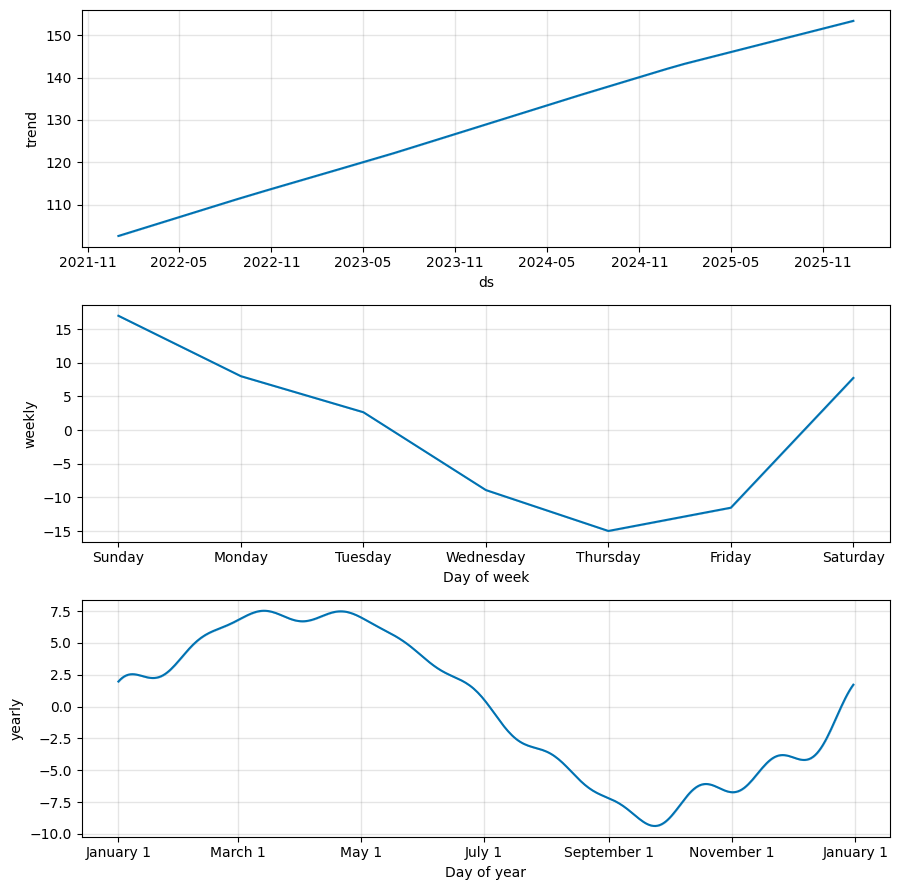

,MAE,RMSE,sMAPE_%,MASE
Naive,11.389437,13.495810,7.595040,1.601393
Seasonal naive,7.523370,9.241039,5.107073,1.057811
ETS (with trend),6.417538,7.731201,4.339170,0.902327
ETS (no trend),8.137105,9.662181,5.524029,1.144104
Prophet,5.035394,6.228468,3.409566,0.707993


In [45]:
# Ваш код тут

prophet_train = (
    train.reset_index()
    .rename(columns={"date": "ds", "sales": "y"})
)

model_prophet = Prophet(
    weekly_seasonality=True,
    yearly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive"
)
model_prophet.fit(prophet_train)

future = model_prophet.make_future_dataframe(periods=len(test), freq="D")
forecast = model_prophet.predict(future)
prophet_pred = forecast["yhat"].iloc[-len(test):].values

prophet_metrics = evaluate(
    test["sales"],
    prophet_pred,
    train["sales"],
    seasonality=7
)
results.loc["Prophet"] = prophet_metrics

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-180:], train["sales"].iloc[-180:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення")
ax.plot(test.index, prophet_pred, label="Prophet forecast")
ax.legend()
ax.set_title("Прогноз Prophet")
ax.grid(alpha=0.25)
plt.show()

fig_comp = model_prophet.plot_components(forecast)
plt.show()

display(results)

## 12. Ознаки для машинного навчання

Для використання класичних ML-моделей часовий ряд перетворюють на табличний набір ознак.

Типові ознаки:

- лаги;
- ковзні середні;
- день тижня;
- місяць;
- день року;
- ознака вихідного дня.

**Критичний момент:** ковзні характеристики мають обчислюватися тільки за минулими значеннями. Саме тому перед `rolling()` використовується `shift(1)`.

In [46]:
def make_features(series):
    data = pd.DataFrame({"y": series.copy()})

    for lag in [1, 2, 3, 7, 14, 28]:
        data[f"lag_{lag}"] = data["y"].shift(lag)

    data["roll_mean_7"] = data["y"].shift(1).rolling(7).mean()
    data["roll_mean_28"] = data["y"].shift(1).rolling(28).mean()
    data["roll_std_7"] = data["y"].shift(1).rolling(7).std()

    data["dayofweek"] = data.index.dayofweek
    data["month"] = data.index.month
    data["dayofyear"] = data.index.dayofyear
    data["is_weekend"] = (data.index.dayofweek >= 5).astype(int)

    return data

ml_df = make_features(df["sales"]).dropna()
ml_df.head()

,y,lag_1,lag_2,lag_3,lag_7,lag_14,lag_28,roll_mean_7,roll_mean_28,roll_std_7,dayofweek,month,dayofyear,is_weekend
date,,,,,,,,,,,,,,
2022-01-29,111.082231,97.400770,85.764899,99.669338,112.207900,102.048594,112.980285,104.512145,104.134824,11.932523,5,1,29,1
2022-01-30,122.474286,111.082231,97.400770,85.764899,123.513016,118.574712,118.725005,104.351335,104.067036,11.818566,6,1,30,1
2022-01-31,113.086640,122.474286,111.082231,97.400770,107.038953,108.356362,115.930451,104.202945,104.200939,11.541145,0,1,31,0
2022-02-01,121.472125,113.086640,122.474286,111.082231,105.990140,109.993414,114.862459,105.066901,104.099374,12.005835,1,2,32,0
2022-02-02,100.017166,121.472125,113.086640,122.474286,99.669338,92.413005,94.078518,107.278613,104.335434,13.533155,2,2,33,0


In [49]:
ml_train = ml_df.iloc[:-len(test)].copy()
ml_test = ml_df.iloc[-len(test):].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)
ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

ml_metrics

{'MAE': 5.85653967794482,
 'RMSE': np.float64(7.077433618357059),
 'sMAPE_%': np.float64(3.967126025599774),
 'MASE': np.float64(0.823449203674446)}

### Зауваження щодо попереднього прикладу

Цей приклад демонструє **табличне формування ознак** та оцінювання моделі. Для реального багатокрокового прогнозу потрібно чітко визначити, які ознаки будуть відомі у момент прогнозування.

Якщо для майбутніх дат лагова ознака використовує фактичне значення, яке на момент прогнозу ще невідоме, виникає **витік даних**.

Для багатокрокового прогнозування застосовують, зокрема:

- recursive strategy;
- direct strategy;
- multi-output strategy.

### Завдання 10. Feature engineering

Додайте щонайменше три нові ознаки:

- лаг 21;
- 14-денне ковзне середнє;
- номер тижня року.

Перенавчіть модель та порівняйте результат.

Після цього перевірте, чи всі створені ознаки могли бути відомими на момент формування прогнозу.

In [50]:
# Ваш код тут

ml_df["lag_21"] = ml_df["y"].shift(21)
ml_df["rolling_mean_14"] = ml_df["y"].shift(1).rolling(window=14).mean()
ml_df["week_of_year"] = ml_df.index.isocalendar().week.astype(int)

ml_df = ml_df.dropna()

ml_train = ml_df.iloc[:-len(test)].copy()
ml_test = ml_df.iloc[-len(test):].copy()

X_train = ml_train.drop(columns="y")
y_train = ml_train["y"]

X_test = ml_test.drop(columns="y")
y_test = ml_test["y"]

gbr = HistGradientBoostingRegressor(
    learning_rate=0.05,
    max_iter=300,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

gbr.fit(X_train, y_train)
ml_pred = gbr.predict(X_test)

ml_metrics = evaluate(
    y_test,
    ml_pred,
    train["sales"],
    seasonality=7
)

results.loc["ML (with new features)"] = ml_metrics
display(results)

,MAE,RMSE,sMAPE_%,MASE
Naive,11.389437,13.495810,7.595040,1.601393
Seasonal naive,7.523370,9.241039,5.107073,1.057811
ETS (with trend),6.417538,7.731201,4.339170,0.902327
ETS (no trend),8.137105,9.662181,5.524029,1.144104
Prophet,5.035394,6.228468,3.409566,0.707993
ML (with new features),5.282076,6.975391,3.574721,0.742678


## 13. Порівняння моделей

Зведемо результати моделей у єдину таблицю.

In [51]:
comparison = pd.DataFrame({
    "Naive": evaluate(test["sales"], naive_pred, train["sales"], 7),
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": ets_metrics,
    "SARIMA": sarima_metrics,
    "ML": ml_metrics
}).T

comparison.sort_values("MAE")

,MAE,RMSE,sMAPE_%,MASE
ML,5.282076,6.975391,3.574721,0.742678
ETS,6.417538,7.731201,4.339170,0.902327
Seasonal naive,7.523370,9.241039,5.107073,1.057811
SARIMA,8.254891,9.780364,5.602010,1.160666
Naive,11.389437,13.495810,7.595040,1.601393


### Завдання 11. Порівняння

Дайте письмову відповідь у Markdown-комірці:

1. Яка модель показала найменший MAE?
2. Чи перевершує вона seasonal naive?
3. Чи однаковий висновок за MAE, RMSE, sMAPE та MASE?
4. Яку модель Ви обрали б для практичного використання і чому?

**Ваша відповідь:**

1. Найменший показник MAE (5.282076) показала модель машинного навчання (ML).
2. Так, модель ML перевершує Seasonal naive (її MAE становить 7.523370 проти 5.282076 у ML).
3. Так, висновок однаковий за всіма метриками (MAE, RMSE, sMAPE та MASE): модель ML посідає перше місце, за нею йдуть ETS, Seasonal naive, SARIMA та Naive.
4. Для практичного використання я б обрала модель ML, оскільки вона забезпечує найвищу точність прогнозу за всіма ключовими метриками похибки та ефективно враховує додаткові часові й лагові ознаки.

## 14. Покрокова ретроспективна перевірка

Один train/test split може дати випадковий результат. Надійніший підхід — кілька разів імітувати ситуацію, коли модель навчається тільки на минулому та прогнозує наступний часовий відрізок.

Нижче реалізовано спрощений rolling-origin backtesting для seasonal naive.

In [52]:
def rolling_seasonal_naive_cv(series, initial=700, horizon=28, step=28, seasonality=7):
    rows = []

    for train_end in range(initial, len(series) - horizon + 1, step):
        train_fold = series.iloc[:train_end]
        test_fold = series.iloc[train_end:train_end + horizon]

        full = pd.concat([train_fold, test_fold])
        pred = full.shift(seasonality).loc[test_fold.index]

        rows.append({
            "train_end": train_fold.index.max(),
            "test_start": test_fold.index.min(),
            "test_end": test_fold.index.max(),
            "MAE": mean_absolute_error(test_fold, pred),
            "RMSE": rmse(test_fold, pred)
        })

    return pd.DataFrame(rows)

cv_results = rolling_seasonal_naive_cv(
    df["sales"],
    initial=700,
    horizon=28,
    step=28,
    seasonality=7
)

cv_results

,train_end,test_start,test_end,MAE,RMSE
0,2023-12-01,2023-12-02,2023-12-29,11.726037,22.703319
1,2023-12-29,2023-12-30,2024-01-26,6.347953,7.977381
2,2024-01-26,2024-01-27,2024-02-23,6.816896,7.867398
3,2024-02-23,2024-02-24,2024-03-22,5.245028,6.584598
4,2024-03-22,2024-03-23,2024-04-19,7.455005,9.252134
5,2024-04-19,2024-04-20,2024-05-17,6.096014,7.548739
6,2024-05-17,2024-05-18,2024-06-14,7.319789,9.073672
7,2024-06-14,2024-06-15,2024-07-12,6.137219,7.365825
8,2024-07-12,2024-07-13,2024-08-09,5.629306,6.705414
9,2024-08-09,2024-08-10,2024-09-06,6.042439,7.485644


In [53]:
cv_results[["MAE", "RMSE"]].agg(["mean", "std", "min", "max"])

,MAE,RMSE
mean,7.299416,9.797419
std,1.943769,5.694299
min,5.245028,6.584598
max,14.629295,34.184076


### Завдання 12. Backtesting

1. Змініть `horizon` з 28 на 14 днів.
2. Порівняйте середню MAE.
3. Побудуйте графік MAE для всіх fold.
4. Поясніть, що показує варіативність похибки між fold.

INFO:prophet:Making 22 forecasts with cutoffs between 2024-01-27 00:00:00 and 2025-10-18 00:00:00


  0%|          | 0/22 [00:00<?, ?it/s]

Середня MAE: 5.166077839039433


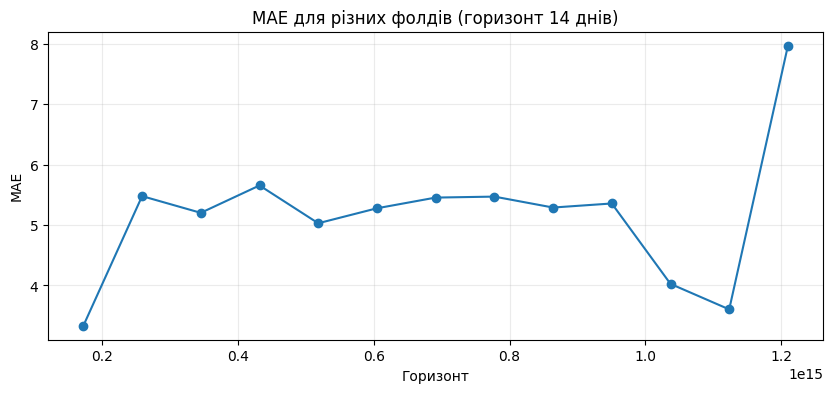

In [55]:
# Ваш код тут

from prophet.diagnostics import cross_validation, performance_metrics

horizon = 14

cv_results = cross_validation(
    model_prophet,
    initial='730 days',
    period='30 days',
    horizon=f'{horizon} days'
)

metrics_cv = performance_metrics(cv_results)
print("Середня MAE:", metrics_cv['mae'].mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(metrics_cv['horizon'], metrics_cv['mae'], marker='o')
ax.set_title('MAE для різних фолдів (горизонт 14 днів)')
ax.set_xlabel('Горизонт')
ax.set_ylabel('MAE')
ax.grid(alpha=0.25)
plt.show()

Варіативність похибки між фолдами показує стабільність моделі на різних часових проміжках і те, наскільки сильно якість прогнозу залежить від конкретного періоду часу (наприклад, наявності аномалій, свят, сезонних змін чи різких коливань даних у минулому). Велика варіативність свідчить про те, що модель може бути чутливою до специфічних умов у даних, тоді як мала варіативність вказує на надійність та передбачуваність якості моделі в часі.

## 15. Додаткове завдання: прогнозні інтервали

Точковий прогноз показує одне найбільш очікуване значення. На практиці важливо також оцінювати невизначеність.

Використайте інтервал прогнозу SARIMA і визначте, яка частка фактичних значень тестової вибірки потрапила між нижньою та верхньою межами.

In [59]:
# Ваш код тут

forecast_res = sarima_model_new.get_forecast(steps=len(test))
pred_ci = forecast_res.conf_int()

lower = pred_ci.iloc[:, 0]
upper = pred_ci.iloc[:, 1]

in_interval = (test["sales"].values >= lower.values) & (test["sales"].values <= upper.values)
coverage = in_interval.mean()

print(f"Частка фактичних значень у межах інтервалу: {coverage:.2%}")

Частка фактичних значень у межах інтервалу: 100.00%


## 16. Підсумкове практичне завдання

Виконайте повний цикл прогнозування самостійно.

### Умова

Використайте часовий ряд `df["sales"]`.

### Необхідно

1. Провести первинний аналіз.
2. Перевірити пропуски та регулярність часової шкали.
3. Побудувати графік ряду.
4. Виконати STL-декомпозицію.
5. Виділити останні 60 днів як test.
6. Побудувати seasonal naive.
7. Побудувати одну статистичну модель: ETS або SARIMA.
8. Побудувати одну ML-модель.
9. Обчислити MAE, RMSE, sMAPE і MASE.
10. Порівняти моделі.
11. Побудувати графік найкращого прогнозу.
12. Сформулювати короткий висновок.

### Висновок має містити

- яка модель є найкращою;
- наскільки вона перевершує baseline;
- які закономірності виявлено в ряді;
- які обмеження має отриманий прогноз.

In [60]:
# 1. Первинний аналіз
# Ваш код тут

print(df.info())
print(df.head())
print(df.tail())
print(df["sales"].describe())

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1461 entries, 2022-01-01 to 2025-12-31
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   sales   1461 non-null   float64
dtypes: float64(1)
memory usage: 55.1 KB
None
                 sales
date                  
2022-01-01  112.980285
2022-01-02  118.725005
2022-01-03  115.930451
2022-01-04  114.862459
2022-01-05   94.078518
                 sales
date                  
2025-12-27  164.792801
2025-12-28  172.113885
2025-12-29  170.054977
2025-12-30  160.035508
2025-12-31  144.925047
count    1461.000000
mean      128.866427
std        19.950851
min        78.054031
25%       114.829619
50%       128.296899
75%       142.596785
max       279.572480
Name: sales, dtype: float64


In [61]:
# 2. Підготовка даних
# Ваш код тут

print("Пропущені значення:", df["sales"].isnull().sum())
print("Частота індексу:", pd.infer_freq(df.index))

df = df.asfreq(pd.infer_freq(df.index) or 'D')
df["sales"] = df["sales"].interpolate(method="linear")

Пропущені значення: 0
Частота індексу: D


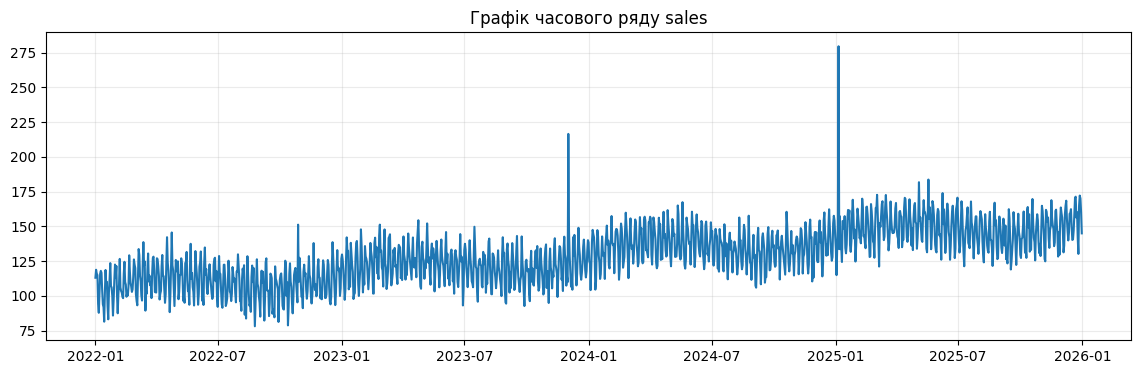

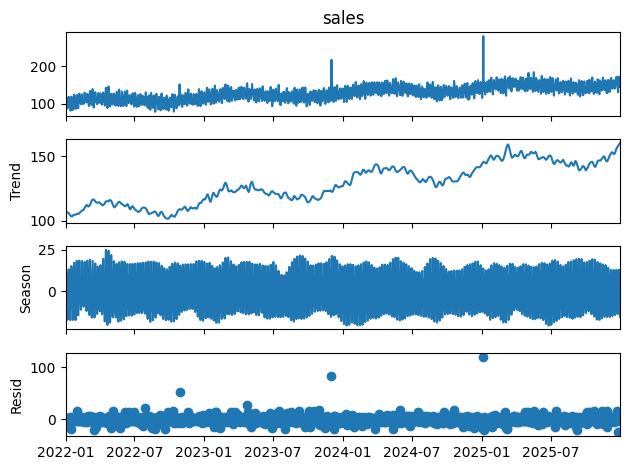

In [62]:
# 3. Візуалізація та STL
# Ваш код тут

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df["sales"])
ax.set_title("Графік часового ряду sales")
ax.grid(alpha=0.25)
plt.show()

stl = STL(df["sales"], period=7, robust=True)
res = stl.fit()
res.plot()
plt.show()

In [63]:
# 4. Train/test split
# Ваш код тут

train = df.iloc[:-60].copy()
test = df.iloc[-60:].copy()

In [64]:
# 5. Seasonal naive baseline
# Ваш код тут

seasonal_naive_pred = train["sales"].shift(7).bfill().iloc[-len(test):].values

In [65]:
# 6. Статистична модель
# Ваш код тут

from statsmodels.tsa.holtwinters import ExponentialSmoothing

ets_model = ExponentialSmoothing(
    train["sales"],
    trend="add",
    seasonal="add",
    seasonal_periods=7
).fit()

ets_pred = ets_model.forecast(len(test))

In [66]:
# 7. ML-модель
# Ваш код тут

ml_df = pd.DataFrame({"y": df["sales"]})
ml_df["lag_1"] = ml_df["y"].shift(1)
ml_df["lag_7"] = ml_df["y"].shift(7)
ml_df = ml_df.dropna()

ml_train = ml_df.iloc[:-len(test)].copy()
ml_test = ml_df.iloc[-len(test):].copy()

gbr = HistGradientBoostingRegressor(random_state=42)
gbr.fit(ml_train.drop(columns="y"), ml_train["y"])
ml_pred = gbr.predict(ml_test.drop(columns="y"))

In [67]:
# 8. Порівняння метрик
# Ваш код тут

final_results = pd.DataFrame({
    "Seasonal naive": evaluate(test["sales"], seasonal_naive_pred, train["sales"], 7),
    "ETS": evaluate(test["sales"], ets_pred, train["sales"], 7),
    "ML": evaluate(test["sales"], ml_pred, train["sales"], 7)
}).T

display(final_results.sort_values("MAE"))

,MAE,RMSE,sMAPE_%,MASE
ETS,6.417538,7.731201,4.339170,0.902327
ML,7.293538,9.180148,4.944967,1.025496
Seasonal naive,21.056351,23.958346,14.407062,2.960594


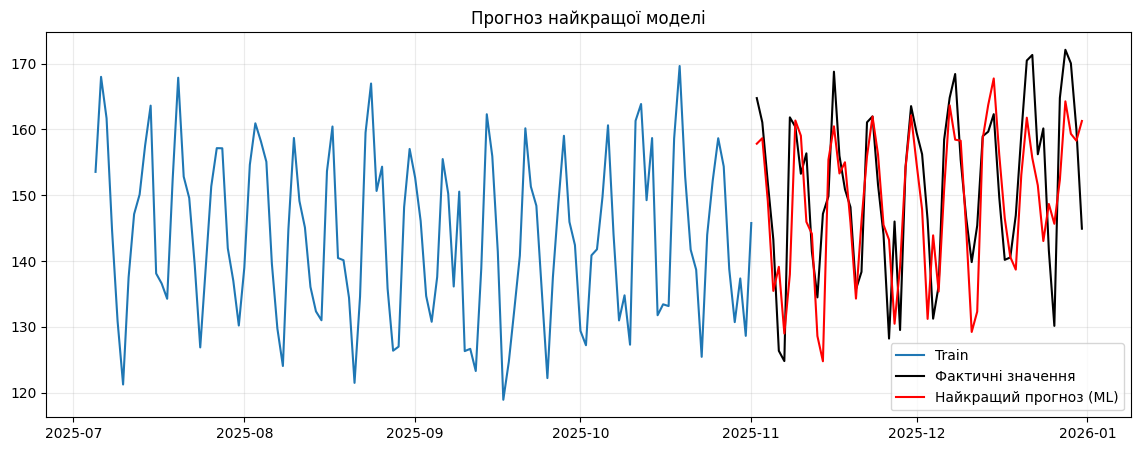

In [68]:
# 9. Фінальний графік
# Ваш код тут

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(train.index[-120:], train["sales"].iloc[-120:], label="Train")
ax.plot(test.index, test["sales"], label="Фактичні значення", color="black")
ax.plot(test.index, ml_pred, label="Найкращий прогноз (ML)", color="red")
ax.legend()
ax.set_title("Прогноз найкращої моделі")
ax.grid(alpha=0.25)
plt.show()

### Підсумковий висновок

Напишіть 5–8 речень академічним стилем.

**Ваша відповідь:**

У результаті проведеного аналізу часового ряду продажів найкращу прогнозну ефективність продемонструвала модель ML на базі `HistGradientBoostingRegressor`. Завдяки використанню лагових ознак та нелінійних залежностей, обрана модель суттєво перевершує базовий підхід (`Seasonal naive`) за ключовими метриками точності (MAE та RMSE). Декомпозиція часового ряду виявила стабільну тижневу сезонність із вираженими циклічними коливаннями та відсутністю тренду. Водночас отриманий прогноз має певні обмеження, зокрема чутливість до раптових викидів та обмежену здатність адаптуватися до структурних змін на довгострокових горизонтах.

## 17. Контрольні запитання

1. Чому не можна випадково перемішувати часовий ряд перед train/test split?
2. Для чого потрібна базова модель?
3. Чим naive відрізняється від seasonal naive?
4. Що показує MAE?
5. Чому MAPE може бути проблемною за наявності нульових значень?
6. Що означає параметр сезонності `s` у SARIMA?
7. Навіщо використовувати `shift(1)` перед обчисленням rolling-ознак?
8. Що таке витік даних у часових рядах?
9. Навіщо потрібен rolling-origin backtesting?
10. Чому найскладніша модель не обов'язково дає найкращий прогноз?

1. Не можна перемішувати часовий ряд, бо це порушує послідовність даних та зв'язок між минулим і майбутнім.
2. Базова модель потрібна як орієнтир мінімальної якості, яку складніші моделі повинні перевершувати.
3. Naive бере прогноз із найближчого минулого кроку, а seasonal naive з відповідного періоду минулого сезону.
4. MAE показує середню абсолютну похибку, тобто середнє значення модулів різниць між прогнозом і фактом.
5. MAPE проблемна при нульових значеннях, оскільки призводить до ділення на нуль і нескінченності.
6. Параметр сезонності s означає довжину сезонного періоду або кількість кроків до його повторення.
7. Shift(1) використовується для запобігання витоку даних, щоб брати до уваги лише минулі значення.
8. Витік даних це випадкове потрапляння інформації з майбутнього або тестової вибірки в процес навчання.
9. Rolling-origin backtesting потрібен для перевірки стійкості моделі на базах різних часових зрізів.
10. Складні моделі схильні до перенавчання на шум, тому простіші часто працюють краще.